### Project #2, Part 2: Web Scraped Data Analysis and Visualizations

### Name: Melanie Samudio

### Date: 11/4/26

In [8]:
import requests

In [9]:
from bs4 import BeautifulSoup

In [10]:
import pandas as pd

In [11]:
import seaborn as sns

In [12]:
import matplotlib.pyplot as plt

In [14]:
# Test the ESPN NBA stats page
#ESPN NBA page was blocked, used basketball-reference website instead.
url = "https://www.Basketball-Reference.com/leagues/NBA_2025.html"

response = requests.get(url, timeout=15)

print(response.status_code)

200


In [15]:
#Find tables on the basketball-ref website
soup = BeautifulSoup(response.text, "html.parser")

tables = soup.find_all("table")

print("Number of tables found:", len(tables))

Number of tables found: 13


In [16]:
#Display id of each table

for table in tables:
    print(table.get("id"))

confs_standings_E
confs_standings_W
divs_standings_E
divs_standings_W
per_game-team
per_game-opponent
totals-team
totals-opponent
per_poss-team
per_poss-opponent
advanced-team
shooting-team
shooting-opponent


In [17]:
#Get NBA team per game stats table
team_table = soup.find("table", id="per_game-team")

#Turn HTML table into a DataFrame
from io import StringIO

df = pd.read_html(StringIO(str(team_table)))[0]

#Display first five rows
df.head()

,Rk,Team,G,MP,FG,FGA,FG%,3P,3PA,3P%,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
0,1.0,Cleveland Cavaliers*,82,240.9,44.5,90.8,0.491,15.9,41.5,0.383,...,0.776,11.2,34.2,45.4,28.1,8.2,4.3,13.2,18.1,121.9
1,2.0,Memphis Grizzlies*,82,240.3,44.8,93.3,0.479,13.9,37.9,0.367,...,0.786,12.9,34.4,47.3,28.4,8.9,5.6,15.7,20.9,121.7
2,3.0,Denver Nuggets*,82,242.1,45.4,89.8,0.506,12.0,31.9,0.376,...,0.770,11.2,34.5,45.7,31.0,8.0,4.9,14.3,17.6,120.8
3,4.0,Oklahoma City Thunder*,82,240.3,44.6,92.7,0.482,14.5,38.8,0.374,...,0.819,10.6,34.2,44.8,26.9,10.3,5.7,11.7,19.9,120.5
4,5.0,Atlanta Hawks,82,241.2,43.4,91.8,0.472,13.5,37.7,0.358,...,0.775,11.9,32.6,44.5,29.6,9.7,5.1,15.5,19.1,118.2


In [18]:
#Check the dataframe- number of rows and columns
print(df.shape)

#Display the column names
print(df.columns.tolist())

(31, 25)
['Rk', 'Team', 'G', 'MP', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', '2P', '2PA', '2P%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS']


In [33]:
# List of NBA Seasons
seasons = [2021, 2022, 2023, 2024, 2025]

#Store the data from each season
all_data = []

for year in seasons :
    url = f"https://www.basketball-reference.com/leagues/NBA_{year}.html"

    response = requests.get(url, timeout=15)
    print(year, response.status_code)

    if response.status_code == 200:
        soup = BeautifulSoup(response.text, "html.parser")
        table = soup.find("table", id = "per_game-team")

        if table is not None:
            season_df = pd.read_html(StringIO(str(table)))[0]
            season_df["Season"] = year
            all_data.append(season_df)



2021 200
2022 200
2023 200
2024 200
2025 200


In [34]:
#Combine all 5 seasons into 1 dataframe
nba_data = pd.concat(all_data, ignore_index=True)

#Check the size of the combined Dataframe
print(nba_data.shape)

#display the first five rows
nba_data.head()

(155, 26)


,Rk,Team,G,MP,FG,FGA,FG%,3P,3PA,3P%,...,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS,Season
0,1.0,Milwaukee Bucks*,72,240.7,44.7,91.8,0.487,14.4,37.1,0.389,...,10.3,37.8,48.1,25.5,8.1,4.6,13.8,17.3,120.1,2021
1,2.0,Brooklyn Nets*,72,241.7,43.1,87.3,0.494,14.2,36.1,0.392,...,8.9,35.5,44.4,26.8,6.7,5.3,13.5,19.0,118.6,2021
2,3.0,Washington Wizards*,72,241.7,43.2,90.9,0.475,10.2,29.0,0.351,...,9.7,35.5,45.2,25.5,7.3,4.1,14.4,21.6,116.6,2021
3,4.0,Utah Jazz*,72,241.0,41.3,88.1,0.468,16.7,43.0,0.389,...,10.6,37.6,48.3,23.7,6.6,5.2,14.2,18.5,116.4,2021
4,5.0,Portland Trail Blazers*,72,240.3,41.3,91.1,0.453,15.7,40.8,0.385,...,10.6,33.9,44.5,21.3,6.9,5.0,11.1,18.9,116.1,2021


In [42]:
# Remove rows not part of NBA teams
nba_data = nba_data[nba_data["Team"] != "League Average"].copy()

#Remove the * from team names
nba_data["Team"] = nba_data["Team"].str.replace("*", "", regex=False)

#Check the cleaned data
print(nba_data.shape)
nba_data.head()


(150, 26)


,Rk,Team,G,MP,FG,FGA,FG%,3P,3PA,3P%,...,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS,Season
0,1.0,Milwaukee Bucks,72,240.7,44.7,91.8,0.487,14.4,37.1,0.389,...,10.3,37.8,48.1,25.5,8.1,4.6,13.8,17.3,120.1,2021
1,2.0,Brooklyn Nets,72,241.7,43.1,87.3,0.494,14.2,36.1,0.392,...,8.9,35.5,44.4,26.8,6.7,5.3,13.5,19.0,118.6,2021
2,3.0,Washington Wizards,72,241.7,43.2,90.9,0.475,10.2,29.0,0.351,...,9.7,35.5,45.2,25.5,7.3,4.1,14.4,21.6,116.6,2021
3,4.0,Utah Jazz,72,241.0,41.3,88.1,0.468,16.7,43.0,0.389,...,10.6,37.6,48.3,23.7,6.6,5.2,14.2,18.5,116.4,2021
4,5.0,Portland Trail Blazers,72,240.3,41.3,91.1,0.453,15.7,40.8,0.385,...,10.6,33.9,44.5,21.3,6.9,5.0,11.1,18.9,116.1,2021


In [43]:
#Check for missing values in each column
print(nba_data.isnull().sum())

Rk        0
Team      0
G         0
MP        0
FG        0
FGA       0
FG%       0
3P        0
3PA       0
3P%       0
2P        0
2PA       0
2P%       0
FT        0
FTA       0
FT%       0
ORB       0
DRB       0
TRB       0
AST       0
STL       0
BLK       0
TOV       0
PF        0
PTS       0
Season    0
dtype: int64


In [44]:
#check for duplicate rows
print(nba_data.duplicated().sum())

0


In [46]:
# Answer 1st research question:How has the average points per game changed during the seasons?

avg_points = nba_data.groupby("Season")["PTS"].mean()

#results
print(avg_points)

Season
2021    112.086667
2022    110.606667
2023    114.686667
2024    114.220000
2025    113.826667
Name: PTS, dtype: float64


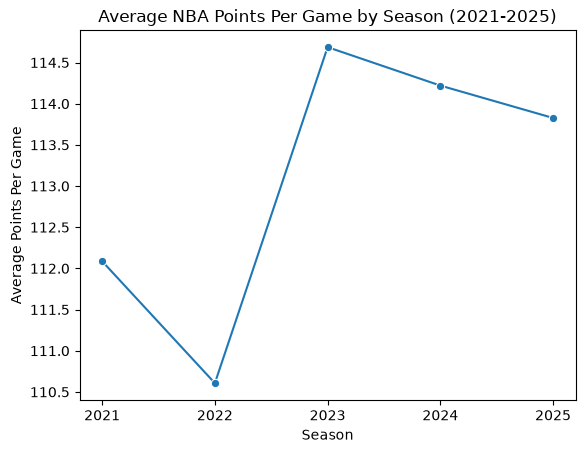

In [49]:
#Plot avg pts per game by season
sns.lineplot(x=avg_points.index, y=avg_points.values, marker="o")

plt.title("Average NBA Points Per Game by Season (2021-2025)")
plt.xlabel("Season")
plt.ylabel("Average Points Per Game")
plt.xticks([2021, 2022, 2023, 2024, 2025])
plt.show()

# Q1 Conclusion:
The average points per game changed over the seasons. The lowest avg was suring the 2021-2022 season at 110.61 points, and the highest average points per game was during the 2022-2023 season with 114.69 points. The scoring increased slightly.

In [50]:
# Answer 2nd research question:Which NBA team has the highest average rebounds per game across the several seasons?

avg_rebounds = nba_data.groupby("Team")["TRB"].mean()

#sort from highest to lowest
avg_rebounds = avg_rebounds.sort_values(ascending=False)

#results
print(avg_rebounds.head(10))

Team
Memphis Grizzlies        46.44
Utah Jazz                46.28
Milwaukee Bucks          46.20
Boston Celtics           45.46
New York Knicks          45.12
Golden State Warriors    45.04
Houston Rockets          44.98
New Orleans Pelicans     44.78
Atlanta Hawks            44.64
Denver Nuggets           44.32
Name: TRB, dtype: float64


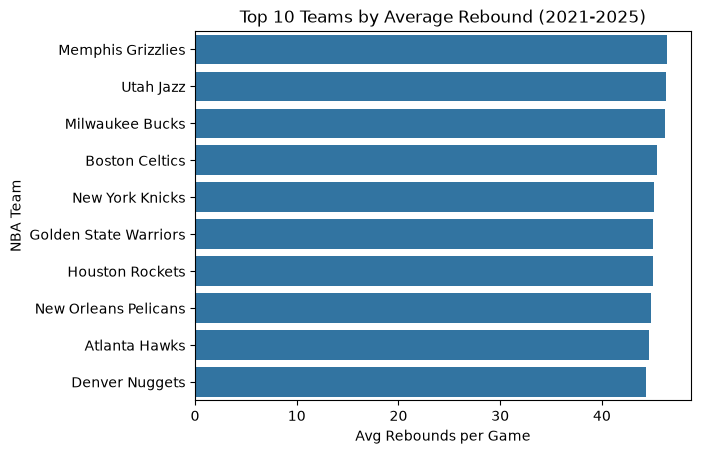

In [52]:
# Plotting top 10 teams with highest avg rebounds
sns.barplot(x=avg_rebounds.head(10).values,
             y=avg_rebounds.head(10).index)

plt.title("Top 10 Teams by Average Rebound (2021-2025)")
plt.xlabel("Avg Rebounds per Game")
plt.ylabel("NBA Team")
plt.show()

# Q2 Conclusion:
The Memphis Grizzlies had the most amount of rebounds per game over the seasons with 46.44 rebounds per game on average. The Utah Jazz then followed with 46.28, and the Milwaukee Bucks with 46.20.

In [53]:
# Answer 3rd research question:How has the average number of assists per game changed across the seasons?

avg_assists = nba_data.groupby("Season")["AST"].mean()

#results
print(avg_assists)

Season
2021    24.806667
2022    24.656667
2023    25.320000
2024    26.673333
2025    26.546667
Name: AST, dtype: float64


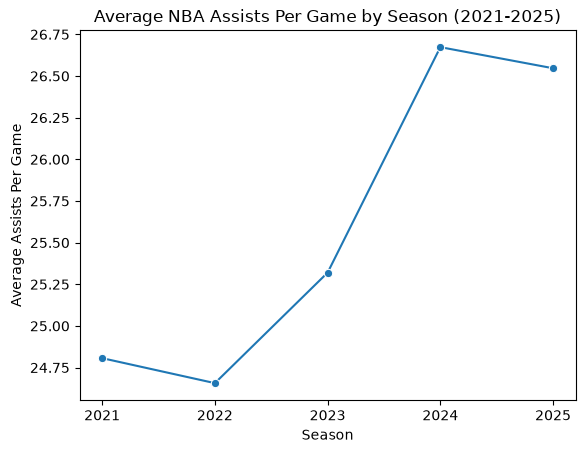

In [56]:
# Plotting average assists per game by season
sns.lineplot(x=avg_assists.index,y=avg_assists.values, marker="o")

plt.title("Average NBA Assists Per Game by Season (2021-2025)")
plt.xlabel("Season")
plt.ylabel("Average Assists Per Game")
plt.xticks([2021, 2022, 2023, 2024, 2025])
plt.show()

# Q3 Conclusion:
The average number of assits increased gradually from 2021-2025. The lowest average was in 2022 with 24.66 assists and the highest in 2024 with 26.67 assists. There was also a bit of a decrease in 2025.

In [61]:
# Answer 4th research question:Which team has the highest number of assists per game over the seasons?
avg_team_assists = nba_data.groupby("Team")["AST"].mean()

#Sort from highest to lowest
avg_team_assists =avg_team_assists.sort_values(ascending=False)

#results
print(avg_team_assists.head(10))

Team
Denver Nuggets            28.80
Golden State Warriors     28.60
Indiana Pacers            27.96
San Antonio Spurs         27.60
Phoenix Suns              27.28
Memphis Grizzlies         26.40
Sacramento Kings          26.26
Minnesota Timberwolves    26.04
Cleveland Cavaliers       26.00
Atlanta Hawks             25.98
Name: AST, dtype: float64


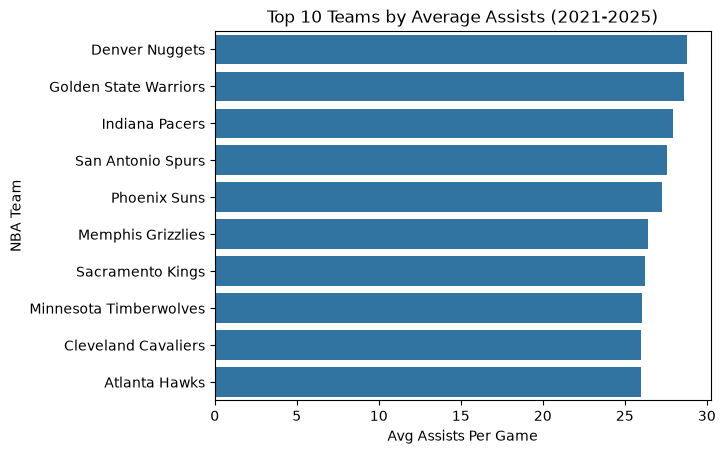

In [62]:
#plotting top 10 teams with highest assists
sns.barplot(x=avg_team_assists.head(10).values,
             y=avg_team_assists.head(10).index)

plt.title("Top 10 Teams by Average Assists (2021-2025)")
plt.xlabel("Avg Assists Per Game")
plt.ylabel("NBA Team")
plt.show()

# Q4 Conclusion:
The Denver Nuggets had the highest level of assists per game over the seasons with 28.80 on average for assists. 